Author: Malik Wensman

Email: mdwensma@ncsu.edu

Class: CSC 251-001 Fall 2026

Program: HW9

Purpose: Digit Classification with Machine Learning

Bugs: None

Acknowledgements: None

Date: 11/05/2026

In [1]:
# load packages
import os
import matplotlib.image as mpimg
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# load train_dataset

train_dataset = []
for label in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]: 
    img_path = os.path.join('./data', 'train', str(label))
    for img in os.listdir(img_path):
        image = mpimg.imread(os.path.join(img_path, img))
        #test for image size and append to train_dataset list if 28x28 pixel image
        if image.shape == (28, 28):
            train_dataset.append((image, label))

#load test_dataset
test_dataset = []
for label in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    img_path = os.path.join('./data', 'test', str(label))
    for img in os.listdir(img_path):
        image = mpimg.imread(os.path.join(img_path, img))
        if image.shape == (28, 28):
            test_dataset.append((image, label))


print('The number of Training Data: ', len(train_dataset))
print('The number of Testing Data: ', len(test_dataset))
print('The size of images: ', train_dataset[0][0].shape)

The number of Training Data:  60000
The number of Testing Data:  10000
The size of images:  (28, 28)


In [4]:
# convert images into vectors
train_images = []
train_labels = []
for image, label in train_dataset:
    train_images.append(image.reshape(1, 784))
    train_labels.append(label)
train_images = np.vstack(train_images)
train_labels = np.array(train_labels)

test_images = []
test_labels = []
for image, label in test_dataset:
    test_images.append(image.reshape(1, 784))
    test_labels.append(label)
test_images = np.vstack(test_images)
test_labels = np.array(test_labels)

print('Training features:', train_images.shape)
print('Training labels:', train_labels.shape)
print('Testing features:', test_images.shape)
print('Testing labels:', test_labels.shape)

Training features: (60000, 784)
Training labels: (60000,)
Testing features: (10000, 784)
Testing labels: (10000,)


In [ ]:
# train the classifier (choose one from the three options)
# Logistic Regression is the classifier run for this submission.
# k Nearest Neighbors and the Support Vector Machine are commented out below.

# Scale pixels to 0-1 and allow more iterations so the solver can converge
classifier = LogisticRegression(max_iter=1000)
classifier.fit(train_images / 255, train_labels)
predictions = classifier.predict(test_images / 255)

In [7]:
# determine accuracy
accuracy = np.sum(predictions == test_labels) / len(test_labels)
print('Accuracy:', accuracy)
# Logistic Regression accuracy on the test dataset: 0.9272 (92.72%)

Accuracy: 0.9272


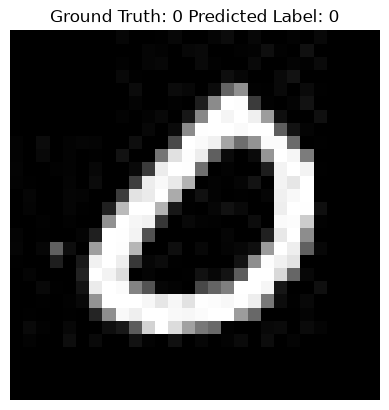

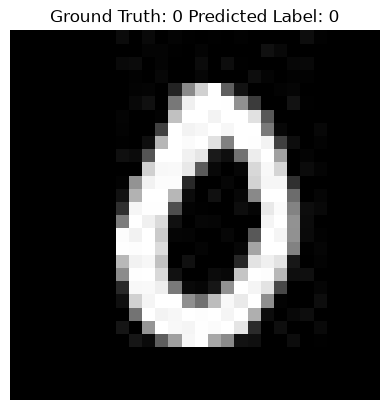

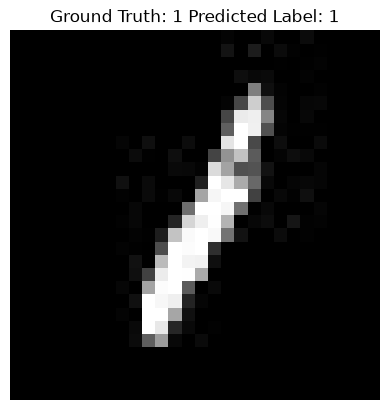

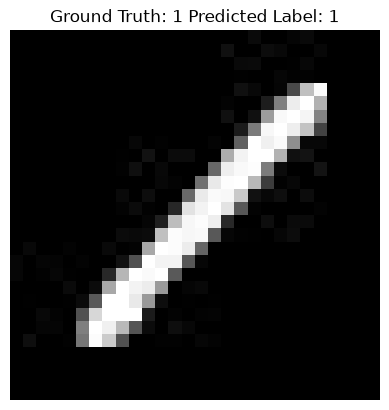

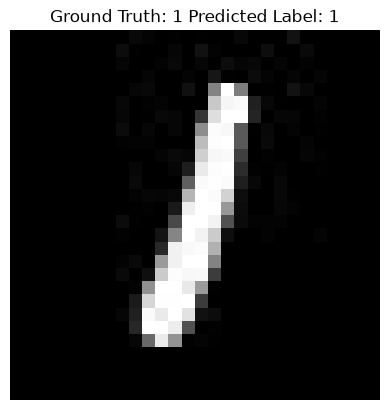

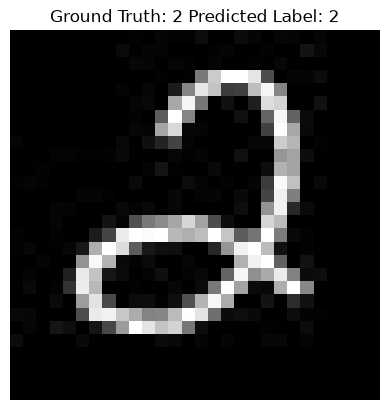

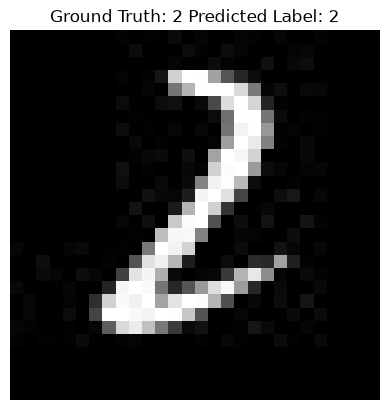

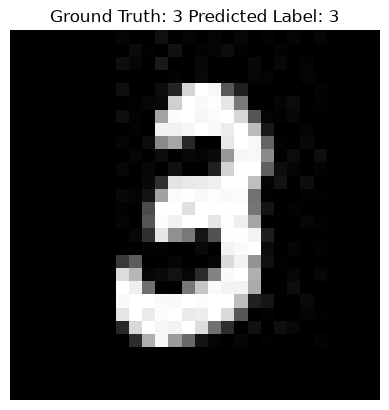

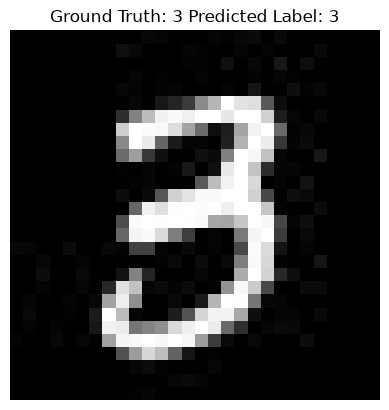

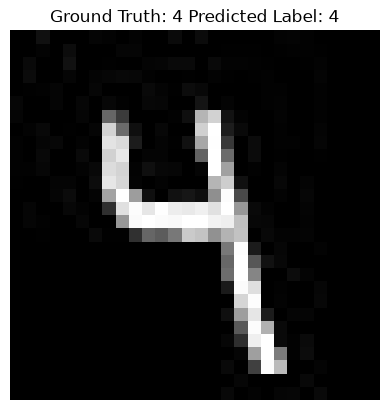

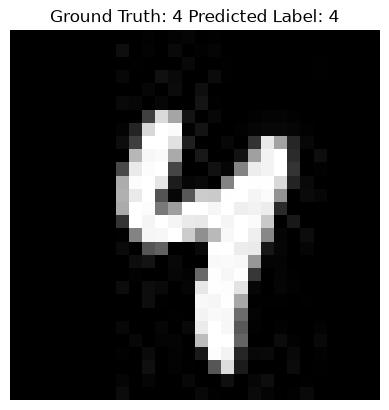

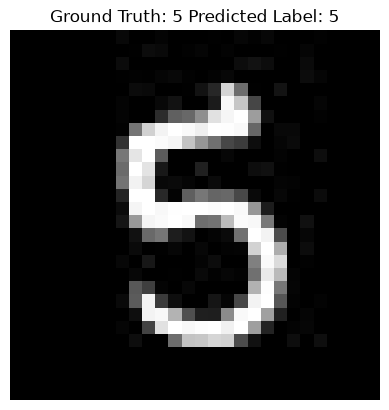

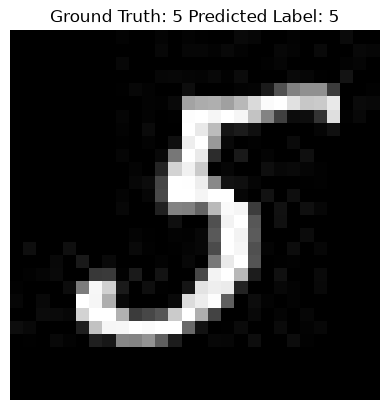

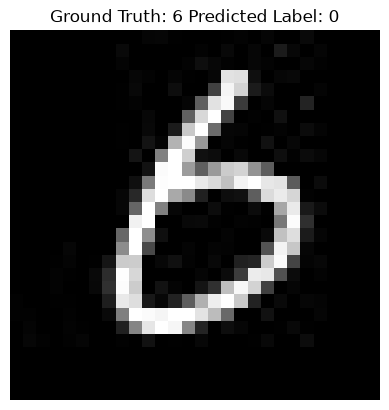

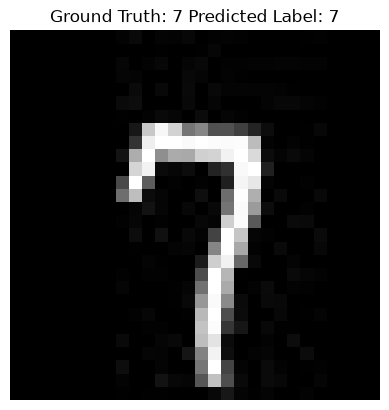

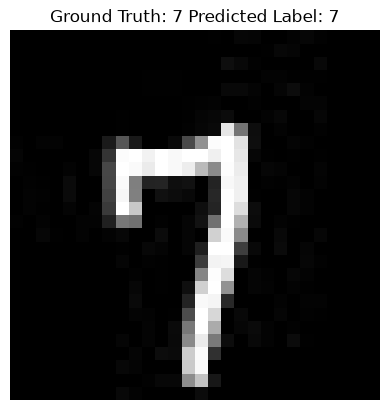

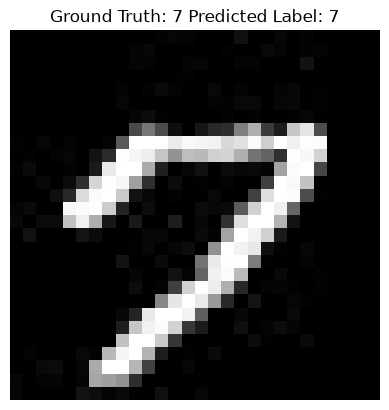

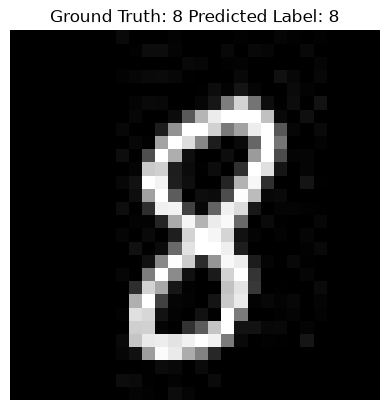

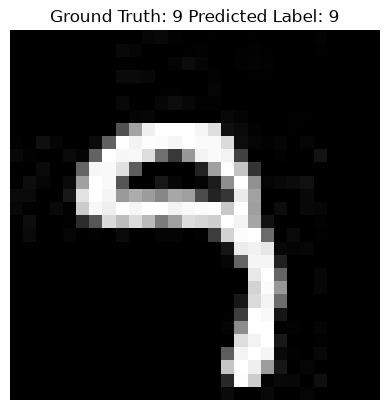

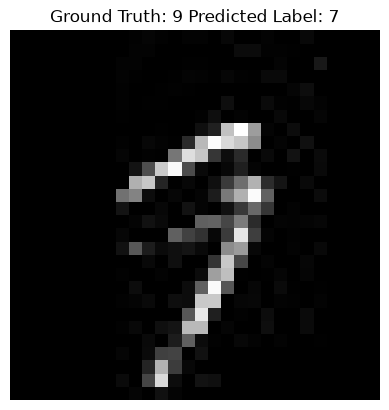

In [8]:
# display every 500th image
for i in range(0, len(test_dataset), 500):
    image, label = test_dataset[i]
    plt.imshow(image, cmap="gray")
    plt.axis('off')
    plt.title(f'Ground Truth: {label} Predicted Label: {predictions[i]}')
    plt.show()

In [ ]:
# k Nearest Neighbors
# classifier = KNeighborsClassifier()
# classifier.fit(train_images / 255, train_labels)
# predictions = classifier.predict(test_images / 255)
# k Nearest Neighbors accuracy on the test dataset: 0.9690 (96.90%)

In [ ]:
# determine accuracy
# accuracy = np.sum(predictions == test_labels) / len(test_labels)
# print('Accuracy:', accuracy)
# k Nearest Neighbors accuracy on the test dataset: 0.9690 (96.90%)

In [ ]:
# display every 500th image
# for i in range(0, len(test_dataset), 500):
#     image, label = test_dataset[i]
#     plt.imshow(image, cmap="gray")
#     plt.axis('off')
#     plt.title(f'Ground Truth: {label} Predicted Label: {predictions[i]}')
#     plt.show()

In [ ]:
# Support Vector Machine
# classifier = LinearSVC()
# classifier.fit(train_images / 255, train_labels)
# predictions = classifier.predict(test_images / 255)
# LinearSVC accuracy on the test dataset: 0.9209 (92.09%)

In [ ]:
# determine accuracy
# accuracy = np.sum(predictions == test_labels) / len(test_labels)
# print('Accuracy:', accuracy)
# LinearSVC accuracy on the test dataset: 0.9209 (92.09%)

In [ ]:
# display every 500th image
# for i in range(0, len(test_dataset), 500):
#     image, label = test_dataset[i]
#     plt.imshow(image, cmap="gray")
#     plt.axis('off')
#     plt.title(f'Ground Truth: {label} Predicted Label: {predictions[i]}')
#     plt.show()

a) I ran this notebook locally in Jupyter on a Linux Mint 22.3 laptop (Lenovo ThinkPad L14).

Accuracy and runtime:
- Logistic Regression: 92.72%, about 49 seconds
- k Nearest Neighbors: 96.90%, about 5 seconds
- LinearSVC: 92.09%, about 63 seconds

k Nearest Neighbors was the most accurate and the fastest. Logistic regression and LinearSVC were both about 92%. LinearSVC was the slowest.

b) k Nearest Neighbors looks at the training images most like the test image and uses their labels. Digits that look similar are usually the same number, so it gets more right. It also just saves the training data, so it ran quickly. Logistic regression and LinearSVC try to separate digits with a straight boundary. Handwritten digits overlap, so those two miss more images and take longer to train.